# 🔬 Análisis Exhaustivo de Falsos Positivos (FP) sobre Noticias Útiles v2 (`is_ruido == False`)

Este notebook realiza la **auditoría programática completa y depuración (v2)** sobre las **27,217 noticias clasificadas como útiles (`is_ruido == False`)** en el periodo **2010–2023** tras la actualización del script de extracción y categorización:
- **Ruta compartida en Cloudflare R2 (Equipo TFM):** `tfm-master-prediccion-bancos-usa/processed/huggingface/df_util/df_util_v2.parquet`.
- **Universo de estudio:** Los 6 grandes bancos de EE. UU. (**US Big 6**: `BAC`, `C`, `GS`, `JPM`, `MS`, `WFC`).

### Estructura del Análisis:
1. **Bloque 1 — Sincronización y Carga de `df_util_v2` desde Cloudflare R2:** Lee directamente desde `processed/huggingface/df_util/df_util_v2.parquet` (y si aún no existe en R2 en la primera ejecución, lo genera desde el nuevo Silver y lo publica automáticamente para que quede disponible para todo el equipo).
2. **Bloque 2 — Diagnóstico de Presencia de la Entidad Bancaria (`Titular` vs. `Fragmento`):** Evalúa en cuántas noticias útiles aparece realmente el nombre/alias del banco.
3. **Bloque 3 — Taxonomía de las 5 Cubetas de Falsos Positivos (`FP_1` a `FP_5`) vs. Núcleo Limpio (`TP`):** Clasifica las 27,217 noticias según las 5 puertas traseras detectadas en la auditoría cualitativa.
4. **Bloque 4 — Inspección Muestral por Cubeta de FP:** Muestra ejemplos aleatorios de cada cubeta de error para validar que no se descartan noticias legítimas.
5. **Bloque 5 — Impacto en la Cobertura Temporal Anual (2010–2023):** Compara los mapas de calor Antes vs. Después de limpiar los Falsos Positivos.
6. **Bloque 6 — Validación Final de Pureza sobre el Núcleo Limpio:** Extrae 5 noticias aleatorias por banco tras la limpieza para verificar la mejora en precisión.

---
## 1. Sincronización y Carga de `df_util_v2` (`is_ruido == False`) en Cloudflare R2

En esta celda conectamos con el bucket `tfm-master-prediccion-bancos-usa` en Cloudflare R2:
* Si el archivo `processed/huggingface/df_util/df_util_v2.parquet` **ya existe en R2**, lo descarga directamente en un par de segundos.
* Si es la **primera ejecución** y aún no se ha subido a `processed/huggingface/df_util/df_util_v2.parquet`, lo filtra automáticamente a partir del dataset Silver actualizado (`is_ruido == False`, `2010–2023`) y **lo sube a R2** para que quede compartido para todo el equipo del Máster sin sobrescribir la versión v1.

In [1]:
import sys
import re
from pathlib import Path
import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.fs as fs
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Resolver ruta hacia 'src' para importar la configuración y diccionarios del proyecto
CURRENT_DIR = Path.cwd().resolve()
SRC_PATH = str(CURRENT_DIR.parent) if CURRENT_DIR.name == "notebooks" else str(CURRENT_DIR / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from config.settings import settings
from shared.tickets import ALIAS_BANCOS, ANALYST_ROLE_TERMS, MACRO_KEYWORDS

# Configurar el sistema de archivos S3/R2
s3_fs = fs.S3FileSystem(
    access_key=settings.aws_access_key_id,
    secret_key=settings.aws_secret_access_key,
    endpoint_override=settings.s3_endpoint_url,
    region=settings.s3_region
)

R2_UTIL_PATH = f"{settings.s3_bucket_name}/processed/huggingface/df_util/df_util_v2.parquet"
R2_SILVER_PATH = f"{settings.s3_bucket_name}/processed/huggingface/multisource_bancos_2010_2023.parquet"

def cargar_o_publicar_df_util() -> pd.DataFrame:
    """Carga df_util_v2 desde R2 (processed/huggingface/df_util/df_util_v2.parquet) o lo crea y sube si aún no existe."""
    info = s3_fs.get_file_info(R2_UTIL_PATH)
    if info.type == fs.FileType.File:
        print(f"✔ Cargando df_util_v2 directamente desde R2: [{R2_UTIL_PATH}] ({info.size / (1024*1024):.2f} MB)...")
        return pq.read_table(R2_UTIL_PATH, filesystem=s3_fs).to_pandas()

    print(f"Archivo aún no encontrado en [{R2_UTIL_PATH}]. Generando desde Silver v2 y subiendo a R2...")
    df_full = pq.read_table(R2_SILVER_PATH, filesystem=s3_fs).to_pandas()
    df_full["datetime"] = pd.to_datetime(df_full["datetime"], errors="coerce", utc=True)
    df_full["year"] = df_full["datetime"].dt.year
    df_u = df_full[(df_full["year"] >= 2010) & (df_full["year"] <= 2023) & (~df_full["is_ruido"])].copy()

    # Subir a Cloudflare R2 en processed/huggingface/df_util/df_util_v2.parquet
    tabla_u = pa.Table.from_pandas(df_u, preserve_index=False)
    pq.write_table(tabla_u, R2_UTIL_PATH, filesystem=s3_fs, compression="zstd")
    info_new = s3_fs.get_file_info(R2_UTIL_PATH)
    print(f"✔ df_util_v2 publicado exitosamente en R2: [{R2_UTIL_PATH}] ({info_new.size / (1024*1024):.2f} MB).")
    return df_u

df_util = cargar_o_publicar_df_util()
print(f"Total noticias útiles v2 cargadas (is_ruido == False): {len(df_util):,} registros x {df_util.shape[1]} columnas.")
display(df_util.head())

Archivo aún no encontrado en [tfm-master-prediccion-bancos-usa/processed/huggingface/df_util/df_util_2010_2023_v2.parquet]. Generando desde Silver v2 y subiendo a R2...
✔ df_util_v2 publicado exitosamente en R2: [tfm-master-prediccion-bancos-usa/processed/huggingface/df_util/df_util_2010_2023_v2.parquet] (13.84 MB).
Total noticias útiles v2 cargadas (is_ruido == False): 27,217 registros x 14 columnas.


,ticker,company_name,cik,date,datetime,title,article,ticker_count,is_multisubject,process_text,category,confianza,is_ruido,year
12,GS,Goldman Sachs Group Inc.,CIK0000886982,2010-01-04 17:01:00,2010-01-04 17:01:00+00:00,"GS: December Trading Volume Slipped, Says Cred...",Shares of Goldman Sachs (GS) are rising with f...,5,True,Shares of Goldman Sachs (GS) are rising with f...,earnings,48.11,False,2010
30,MS,Morgan Stanley,CIK0000895421,2010-01-04 22:23:00,2010-01-04 22:23:00+00:00,"Morgan Stanley: Credit Suisse, UBS Up to ""Buy,...","As mentioned earlier, Morgan Stanley (MS) rece...",5,True,"As mentioned earlier, Morgan Stanley (MS) rece...",m&a,46.54,False,2010
43,GS,Goldman Sachs Group Inc.,CIK0000886982,2010-01-05 16:20:00,2010-01-05 16:20:00+00:00,Analyst cuts broker estimates on trading slowdown,Pali Research scales back fourth-quarter profi...,2,True,Pali Research scales back fourth-quarter profi...,earnings,48.80,False,2010
44,MS,Morgan Stanley,CIK0000895421,2010-01-05 16:20:00,2010-01-05 16:20:00+00:00,Analyst cuts broker estimates on trading slowdown,Pali Research scales back fourth-quarter profi...,2,True,Pali Research scales back fourth-quarter profi...,earnings,48.80,False,2010
47,GS,Goldman Sachs Group Inc.,CIK0000886982,2010-01-05 16:29:00,2010-01-05 16:29:00+00:00,GS: Pali Cuts Estimates on Trading,"Financials are broadly higher today, with Gold...",5,True,"Financials are broadly higher today, with Gold...",earnings,45.38,False,2010


---
## 2. Radiografía de Presencia de la Entidad Bancaria (`Titular` vs. `Fragmento`)

Antes de clasificar los Falsos Positivos, evaluamos en cuántas de las **27,217 noticias útiles (`df_util_v2`)** aparece realmente el nombre o alias oficial del banco asignado en `ticker`:
1. **`banco_en_title`:** ¿El titular (`title`) menciona explícitamente al banco?
2. **`banco_en_ctx`:** ¿El fragmento procesado (`process_text`) menciona explícitamente al banco?
3. **`sin_cuerpo`:** ¿El registro carece de cuerpo extraído (`process_text == '(Titular directo sin cuerpo)'`)?

In [2]:
# Patrones regex por banco basados en shared/tickets.py + nombres históricos de CEOs/entidades
PATRONES_BANCOS = {
    "JPM": r"\b(JPM|JPMorgan|J\.P\. Morgan|JP Morgan|Chase|Dimon)\b",
    "BAC": r"\b(BAC|Bank of America|B of A|BofA|Merrill|Moynihan)\b",
    "C":   r"\b(Citigroup|Citi|Citibank|Fraser|Corbat|Pandit)\b|\(\s*C\s*\)|NYSE:\s*C\b",
    "WFC": r"\b(WFC|Wells Fargo|Wells|Scharf|Stumpf|Sloan)\b",
    "GS":  r"\b(GS|Goldman|Goldman Sachs|Solomon|Blankfein)\b",
    "MS":  r"\b(MS|Morgan Stanley|Gorman|Ted Pick)\b",
}

TAG_SIN_CUERPO = "(Titular directo sin cuerpo)"
df_util["sin_cuerpo"] = df_util["process_text"] == TAG_SIN_CUERPO

# Evaluar presencia del propio banco en titular y en fragmento
df_util["banco_en_title"] = [
    bool(re.search(PATRONES_BANCOS[t], str(ti), re.IGNORECASE))
    for t, ti in zip(df_util["ticker"], df_util["title"])
]
df_util["banco_en_ctx"] = [
    False if sc else bool(re.search(PATRONES_BANCOS[t], str(ct), re.IGNORECASE))
    for t, ct, sc in zip(df_util["ticker"], df_util["process_text"], df_util["sin_cuerpo"])
]

# Clasificar el tipo de anclaje de la entidad en 4 cuadrantes
condiciones_anclaje = [
    df_util["banco_en_title"] & df_util["banco_en_ctx"],
    df_util["banco_en_title"] & df_util["sin_cuerpo"],
    df_util["banco_en_title"] & (~df_util["sin_cuerpo"]) & (~df_util["banco_en_ctx"]),
    (~df_util["banco_en_title"]) & df_util["banco_en_ctx"],
    (~df_util["banco_en_title"]) & (~df_util["banco_en_ctx"]) & df_util["sin_cuerpo"],
    (~df_util["banco_en_title"]) & (~df_util["banco_en_ctx"]) & (~df_util["sin_cuerpo"]),
]
etiquetas_anclaje = [
    "1. Anclaje Doble (Banco en Titular y Cuerpo)",
    "2. Titular Flash Válido (Banco en Titular, Sin Cuerpo)",
    "3. Banco en Titular, Cuerpo Fallback",
    "4. Solo en Cuerpo (Titular NO menciona al banco)",
    "5. Huérfano Sin Cuerpo (NI en Titular NI Cuerpo) [FP]",
    "6. Fallback Sin Banco (Con Cuerpo, pero NI en Titular NI Cuerpo) [FP]",
]
df_util["tipo_anclaje"] = np.select(condiciones_anclaje, etiquetas_anclaje, default="Otro")

resumen_anclaje = (
    df_util["tipo_anclaje"]
    .value_counts()
    .rename_axis("Tipo de Anclaje de Entidad")
    .reset_index(name="Noticias")
)
resumen_anclaje[f"% sobre Útiles ({len(df_util):,})"] = (resumen_anclaje["Noticias"] / len(df_util) * 100).round(2)

print("=" * 95)
print("DIAGNÓSTICO DE PRESENCIA DEL BANCO EN NOTICIAS ÚTILES (is_ruido == False)")
print("=" * 95)
display(resumen_anclaje)

DIAGNÓSTICO DE PRESENCIA DEL BANCO EN NOTICIAS ÚTILES (is_ruido == False)


,Tipo de Anclaje de Entidad,Noticias,"% sobre Útiles (27,217)"
0,4. Solo en Cuerpo (Titular NO menciona al banco),12050,44.27
1,"2. Titular Flash Válido (Banco en Titular, Sin...",6944,25.51
2,1. Anclaje Doble (Banco en Titular y Cuerpo),6841,25.14
3,"3. Banco en Titular, Cuerpo Fallback",832,3.06
4,"6. Fallback Sin Banco (Con Cuerpo, pero NI en ...",408,1.50
5,5. Huérfano Sin Cuerpo (NI en Titular NI Cuerp...,142,0.52


---
## 3. Taxonomía Exhaustiva de Falsos Positivos: Las 5 Cubetas de Error vs. Núcleo Limpio (`TP`)

Aplicamos de forma jerárquica y mutuamente excluyente las **5 reglas de detección de Falsos Positivos** documentadas en `FP_origen_auditoria_zero_shot.md`:
1. **`FP_1_Huerfano_Sin_Cuerpo`:** `process_text == '(Titular directo sin cuerpo)'` y el titular no menciona ni al banco ni términos colectivos de banca (`banks`, `banking`, `financials`, `stress test`).
2. **`FP_2_Fallback_Sin_Banco`:** Tiene texto en `process_text`, pero **ni el titular ni el fragmento mencionan al banco** y el titular tampoco habla explícitamente del sector bancario.
3. **`FP_3_Cross_Bank_Bleed`:** El titular menciona explícitamente a **otro banco competidor** del *Big 6*, **no** menciona al banco del `ticker` (ni habla de `banks` en plural) y el fragmento no contiene comparativas conjuntas.
4. **`FP_4_Rol_Analista_Pronostico`:** El titular no menciona al banco (habla de otra empresa) y el fragmento presenta jerga de analista/recomendación (`downgrade/upgrade from`, `price target`, `analyst`, `maintains`, `initiates`), o el banco solo emite un pronóstico macroeconómico general (`cuts/raises forecast for GDP/inflation/oil`).
5. **`FP_5_Plantilla_13F_ETF_TV`:** Notas robotizadas de carteras de fondos (`% of the total portfolio`, `ETF Inflow Alert`) o listas televisivas multi-sector sin cuerpo (`Fast Money Picks`, `Stocks in focus`).
6. **`TP_Nucleo_Limpio`:** Noticias que superan los 5 filtros y constituyen la señal financiera depurada.

In [3]:
# Términos explícitos del sector bancario que justifican una noticia sistémica aunque no nombre al ticker en el titular
PATRON_SECTOR_BANCARIO = r"\b(?:banks?|banking|big banks|wall street banks|financial stocks|financials|stress tests?|ccar|fdic|bank reg|dodd-frank)\b"

# Patrones ampliados de rol de analista sobre terceros y pronósticos macro de casa de estudios
PATRON_ANALISTA_AMPLIADO = (
    r"\b(?:upgrades?|downgrades?|upgraded|downgraded|initiates?|reiterates?|maintains?|"
    r"price target|target price|cut to|raised to|analyst|analysts|strategist|strategists|"
    r"economist|economists|note to clients|equity research|top picks?|estimates?)\b"
)
PATRON_PRONOSTICO_CASA = r"\b(?:cuts? forecast|raises? forecast|cuts? target|gdp forecast|economic growth target|warns bond traders)\b"

# Patrones de plantillas robotizadas 13F / ETFs y listas de TV sin cuerpo
PATRON_13F_ETF = r"(?:% of the total portfolio|shares,\s*\d+\.\d+% of|etf inflow alert|etf outflow alert|13f|holdings page)"
PATRON_LISTA_TV = r"(?:fast money picks|final trade|stocks in focus|stocks to watch)"

# Precalcular señales auxiliares vectorizadas
t_str = df_util["title"].astype(str)
c_str = df_util["process_text"].astype(str)

df_util["sector_bancario_en_title"] = t_str.str.contains(PATRON_SECTOR_BANCARIO, case=False, regex=True)
df_util["jerga_analista"] = c_str.str.contains(PATRON_ANALISTA_AMPLIADO, case=False, regex=True)
df_util["pronostico_casa"] = t_str.str.contains(PATRON_PRONOSTICO_CASA, case=False, regex=True) | c_str.str.contains(PATRON_PRONOSTICO_CASA, case=False, regex=True)
df_util["es_plantilla_13f"] = t_str.str.contains(PATRON_13F_ETF, case=False, regex=True) | c_str.str.contains(PATRON_13F_ETF, case=False, regex=True)
df_util["es_lista_tv"] = t_str.str.contains(PATRON_LISTA_TV, case=False, regex=True) & df_util["sin_cuerpo"]

# Detectar si el titular menciona a OTRO banco competidor pero NO al banco del ticker
def menciona_otro_banco_en_title(row_ticker: str, title_text: str) -> bool:
    for otro_tk, pat in PATRONES_BANCOS.items():
        if otro_tk != row_ticker and re.search(pat, title_text, re.IGNORECASE):
            return True
    return False

df_util["otro_banco_en_title"] = [
    False if bt else menciona_otro_banco_en_title(tk, str(ti))
    for tk, ti, bt in zip(df_util["ticker"], df_util["title"], df_util["banco_en_title"])
]

# Reglas jerárquicas de asignación de cubetas de FP
c_fp1 = df_util["sin_cuerpo"] & (~df_util["banco_en_title"]) & (~df_util["sector_bancario_en_title"])
c_fp2 = (~df_util["sin_cuerpo"]) & (~df_util["banco_en_title"]) & (~df_util["banco_en_ctx"]) & (~df_util["sector_bancario_en_title"])
c_fp5 = df_util["es_plantilla_13f"] | df_util["es_lista_tv"]
c_fp4 = ((~df_util["banco_en_title"]) & (~df_util["sector_bancario_en_title"]) & df_util["jerga_analista"]) | df_util["pronostico_casa"]
c_fp3 = df_util["otro_banco_en_title"] & (~df_util["sector_bancario_en_title"]) & (~c_str.str.contains(r"\b(?:other|peers|rivals|megabanks|big banks|compared to|along with|including)\b", case=False, regex=True))

df_util["fp_bucket"] = np.select(
    [c_fp1, c_fp2, c_fp5, c_fp4, c_fp3],
    [
        "FP_1: Huérfana Sin Cuerpo ni Banco",
        "FP_2: Fallback Con Cuerpo pero Sin Banco",
        "FP_5: Plantilla 13F / ETF / Lista TV",
        "FP_4: Banco como Analista / Pronóstico Macro",
        "FP_3: Otro Banco en Titular (Cross-Bleed)",
    ],
    default="TP: Núcleo Limpio (Señal Válida)",
)
df_util["es_fp_detectado"] = df_util["fp_bucket"] != "TP: Núcleo Limpio (Señal Válida)"

# 1. Tabla Resumen Global de Cubetas
tabla_global_fp = (
    df_util["fp_bucket"]
    .value_counts()
    .rename_axis("Cubeta de Auditoría")
    .reset_index(name="Noticias")
)
tabla_global_fp["% sobre Total Útiles"] = (tabla_global_fp["Noticias"] / len(df_util) * 100).round(2)

total_fp = int(df_util["es_fp_detectado"].sum())
total_tp = int((~df_util["es_fp_detectado"]).sum())
print("=" * 95)
print(f"BALANCE GLOBAL DE AUDITORÍA SOBRE {len(df_util):,} NOTICIAS ÚTILES:")
print(f"  ✔ Señal Limpia (TP):         {total_tp:>7,} noticias ({total_tp / len(df_util) * 100:.2f}%)")
print(f"  ✖ Falsos Positivos (FP 1-5): {total_fp:>7,} noticias ({total_fp / len(df_util) * 100:.2f}%)")
print("=" * 95)
display(tabla_global_fp)

# 2. Desglose por Banco
piv_banco_fp = pd.crosstab(df_util["ticker"], df_util["fp_bucket"], margins=True, margins_name="TOTAL")
piv_banco_fp["%_FP_Total"] = (
    df_util.groupby("ticker")["es_fp_detectado"].mean().mul(100).round(1)
)
piv_banco_fp.loc["TOTAL", "%_FP_Total"] = round(df_util["es_fp_detectado"].mean() * 100, 1)
print("\nDESGLOSE DE CUBETAS DE FP POR BANCO (CONTEO Y % DE FP):")
display(piv_banco_fp)

BALANCE GLOBAL DE AUDITORÍA SOBRE 27,217 NOTICIAS ÚTILES:
  ✔ Señal Limpia (TP):          25,551 noticias (93.88%)
  ✖ Falsos Positivos (FP 1-5):   1,666 noticias (6.12%)


,Cubeta de Auditoría,Noticias,% sobre Total Útiles
0,TP: Núcleo Limpio (Señal Válida),25551,93.88
1,FP_4: Banco como Analista / Pronóstico Macro,818,3.01
2,FP_3: Otro Banco en Titular (Cross-Bleed),672,2.47
3,FP_5: Plantilla 13F / ETF / Lista TV,105,0.39
4,FP_2: Fallback Con Cuerpo pero Sin Banco,57,0.21
5,FP_1: Huérfana Sin Cuerpo ni Banco,14,0.05



DESGLOSE DE CUBETAS DE FP POR BANCO (CONTEO Y % DE FP):


fp_bucket,FP_1: Huérfana Sin Cuerpo ni Banco,FP_2: Fallback Con Cuerpo pero Sin Banco,FP_3: Otro Banco en Titular (Cross-Bleed),FP_4: Banco como Analista / Pronóstico Macro,FP_5: Plantilla 13F / ETF / Lista TV,TP: Núcleo Limpio (Señal Válida),TOTAL,%_FP_Total
ticker,,,,,,,,
BAC,6,10,55,23,26,2733,2853,4.2
C,0,0,194,237,14,3806,4251,10.5
GS,0,9,130,162,19,4793,5113,6.3
JPM,2,23,61,37,1,4238,4362,2.8
MS,4,7,136,150,13,4979,5289,5.9
WFC,2,8,96,209,32,5002,5349,6.5
TOTAL,14,57,672,818,105,25551,27217,6.1


---
## 4. Auditoría Visual por Cubeta de Falso Positivo (5 Ejemplos por Cubeta)

Para verificar que cada una de las 5 reglas (`FP_1` a `FP_5`) captura auténtico ruido sin eliminar noticias fundamentales de los bancos, extraemos una muestra aleatoria de **5 noticias por cada cubeta de FP**.

In [4]:
pd.set_option("display.max_colwidth", None)
cols_vista = ["date", "ticker", "category", "confianza", "fp_bucket", "title", "process_text"]

for bucket_name in sorted(df_util.loc[df_util["es_fp_detectado"], "fp_bucket"].unique()):
    sub = df_util[df_util["fp_bucket"] == bucket_name]
    print("=" * 105)
    print(f"🔍 {bucket_name} — Total en cubeta: {len(sub):,} noticias ({len(sub)/len(df_util)*100:.2f}%)")
    print("=" * 105)
    display(sub.sample(n=min(5, len(sub)), random_state=42)[cols_vista].reset_index(drop=True))

🔍 FP_1: Huérfana Sin Cuerpo ni Banco — Total en cubeta: 14 noticias (0.05%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2019-06-04 00:00:00,WFC,macro,31.24,FP_1: Huérfana Sin Cuerpo ni Banco,Shares of several companies in the financial sector are trading higher amid renewed global economic optimism following comments from China's Commerce Ministry indicating the country is open to dialogue to resolve trade tenisons. Mexico trade concerns also eased after GOP lawmakers reportedly implied they would work to prevent Mexico tariffs and Mexican officials said it could find common ground with the US.,(Titular directo sin cuerpo)
1,2019-06-04 00:00:00,BAC,macro,31.24,FP_1: Huérfana Sin Cuerpo ni Banco,Shares of several companies in the financial sector are trading higher amid renewed global economic optimism following comments from China's Commerce Ministry indicating the country is open to dialogue to resolve trade tenisons. Mexico trade concerns also eased after GOP lawmakers reportedly implied they would work to prevent Mexico tariffs and Mexican officials said it could find common ground with the US.,(Titular directo sin cuerpo)
2,2010-03-17 00:00:00,MS,macro,38.74,FP_1: Huérfana Sin Cuerpo ni Banco,Strategists Warn About The Financial Sector As The Financial ETF Sets A New 52-Week High,(Titular directo sin cuerpo)
3,2019-06-04 13:49:00,BAC,macro,31.24,FP_1: Huérfana Sin Cuerpo ni Banco,Shares of several companies in the financial sector are trading higher amid renewed global economic optimism following comments from China's Commerce Ministry indicating the country is open to dialogue to resolve trade tenisons. Mexico trade concerns also eased after GOP lawmakers reportedly implied they would work to prevent Mexico tariffs and Mexican officials said it could find common ground with the US.,(Titular directo sin cuerpo)
4,2018-03-23 00:00:00,BAC,macro,66.48,FP_1: Huérfana Sin Cuerpo ni Banco,The Fed Hikes Rates Ahead Of Upcoming Financial Sector Earnings,(Titular directo sin cuerpo)


🔍 FP_2: Fallback Con Cuerpo pero Sin Banco — Total en cubeta: 57 noticias (0.21%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2010-05-27 20:49:00,BAC,macro,45.60,FP_2: Fallback Con Cuerpo pero Sin Banco,Financial sector rallies in relief over China,"The U.S. financial sector reverses the previous session’s losses Thursday, rising more than 4% after China and Kuwait deny reports they was reviewing their European debt holdings. Meanwhile, a White House official says the Obama administration will keep lobbying Congress on the so-called Volcker rule."
1,2011-03-18 17:01:00,GS,macro,50.26,FP_2: Fallback Con Cuerpo pero Sin Banco,Fed gives green light for dividend hikes,Fed notes that 19 banks added $25 billion in earnings since 2008\n\nThe Federal Reserve gives some big banks the green light to hike dividends and snap up shares in a development that have some worried that the approach will result in banks reducing their equity and raising their leverage.
2,2017-03-01 15:17:00,MS,macro,44.61,FP_2: Fallback Con Cuerpo pero Sin Banco,Financial ETF hits highest level since 2007 on rate hike hopes,"Goldman Sachs hits a new record\n\nExchange-traded funds tied to the financial sector jumped on Wednesday, as expectations grew that the Federal Reserve could raise interest rates at its March meeting."
3,2012-03-14 19:28:00,JPM,macro,53.64,FP_2: Fallback Con Cuerpo pero Sin Banco,Treasury yields jump most since October,"U.S. sells 30-year bonds at highest yield since August\n\nTreasury prices extend losses from the prior session, when the Federal Reserve sounded slightly more comfortable with the economic outlook and most U.S. banks passed their stress tests."
4,2018-03-28 13:53:00,JPM,macro,44.39,FP_2: Fallback Con Cuerpo pero Sin Banco,Financial sector poised for worst month since January 2016,"The U.S. financial sector inched higher on Wednesday, setting it up for a slight rebound following a sharp decline, but it remained on track for its worst monthly performance in more than two years. The sector rose 0.2%, while the Financial Select Sector SPDR ETF rose 0.7% in the first half-hour of trading, which is typically a more volatile period. The Dow Jones Industrial Average rose 0.3% whi"


🔍 FP_3: Otro Banco en Titular (Cross-Bleed) — Total en cubeta: 672 noticias (2.47%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2018-09-20 00:00:00,MS,m&a,50.95,FP_3: Otro Banco en Titular (Cross-Bleed),Is Goldman Sachs Mulling the Spin-Off of Fintech App Simon?,"ing stake holders in the app is expected to increase the usage of the app. Notably, a rival structured notes sales platform - Luma - was announced by Morgan Stanley(MS) and BofA in July."
1,2015-09-23 00:00:00,C,governance,59.78,FP_3: Otro Banco en Titular (Cross-Bleed),"BofA CEO Unscathed After Crucial Vote, to Remain Chairman","Among the major U.S. banks like JPMorgan Chase & Co. JPM , Wells Fargo & Company WFC and Citigroup Inc. C , only Citigroup has a separate chairman and CEO."
2,2021-01-29 00:00:00,GS,governance,39.46,FP_3: Otro Banco en Titular (Cross-Bleed),Wells Fargo CEO Scharf's pay drops nearly 12% in 2020,The fall in Scharf's pay compares with a 36% drop in Goldman Sachs GS.N Chief Executive David Solomon's salary and a 20% jump in compensation for Morgan Stanley's MS.N top boss James Gorman. JPMorgan held CEO Dimon's annual pay at $31.5 million.
3,2023-09-22 08:11:34,JPM,macro,42.78,FP_3: Otro Banco en Titular (Cross-Bleed),"UPDATE 1-Citi, BofA see India's 10-yr bond yield sub-7% post index inclusion","JPMorgan's decision to include local Indian bonds in its widely tracked emerging market debt index could boost demand for debt and push India's benchmark 10-year bond yield to sub-7% levels in the coming months, Citi and Bank of America said on Friday. India"
4,2017-08-22 00:00:00,C,m&a,53.45,FP_3: Otro Banco en Titular (Cross-Bleed),"Financial Sector Update for 08/22/2017: JPM, BAC, WFC, C, USB, GS, KKR","In sector news, Citigroup ( C ) said late Monday that Muir Paterson will join the firm's corporate and investment banking division as the global head of strategic shareholder advisory in its M&A Group. In this newly created role, Paterson, who will be based in New York City,"


🔍 FP_4: Banco como Analista / Pronóstico Macro — Total en cubeta: 818 noticias (3.01%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2016-04-15 00:00:00,WFC,earnings,57.23,FP_4: Banco como Analista / Pronóstico Macro,"Citi (C) Beats Q1 Earnings, Results Show Industry Challenges","Wells Fargo & Company's WFC first-quarter 2016 earnings recorded a positive surprise of about 1%. Earnings of 99 cents per share beat the Zacks Consensus Estimate by a penny. However, it compared unfavorably with the prior-year quarter's earnings of $1.04 per s"
1,2019-04-16 13:33:00,BAC,earnings,61.60,FP_4: Banco como Analista / Pronóstico Macro,Stocks climb toward records after corporate earnings,"way from its record close set in Sept. 20. Earnings from BlackRock Inc. came in higher than analysts' expectations, while first-quarter revenues for Bank of America Corp. fell short of forecasts. Investors will maintain a close eye on the financial sector's earnings as banks juggle with falling interest margins and slower U.S. growth. In other company news, shares of UnitedHealth Group Inc. rose 3% after its"
2,2023-10-19 00:00:00,WFC,earnings,61.21,FP_4: Banco como Analista / Pronóstico Macro,Ally Financial (ALLY) Beats on Q3 Earnings Despite Higher Costs,Wells Fargo & Company’s WFC third-quarter 2023 adjusted earnings per share of $1.39 outpaced the Zacks Consensus Estimate of $1.25. The figure improved 6.9% year over year. The adjusted figure excludes the impact of discrete tax benefits relating to the resolut
3,2021-01-04 00:00:00,GS,earnings,39.98,FP_4: Banco como Analista / Pronóstico Macro,"US STOCKS-S&P 500, Dow aim record open as economic rebound hopes fuel rally","Shares of Goldman Sachs GS.N and Morgan Stanley MS.N rose about 1% each, outperforming other U.S. lenders, after Barclays upgraded its ratings on both stocks to ""overweight""."
4,2023-10-20 00:00:00,WFC,earnings,62.53,FP_4: Banco como Analista / Pronóstico Macro,"Regions Financial (RF) Q3 Earnings & Revenues Miss, Loans Rise",Wells Fargo & Company’s WFC third-quarter 2023 adjusted earnings per share of $1.39 outpaced the Zacks Consensus Estimate of $1.25. The figure improved 6.9% year over year. The adjusted figure excludes the impacts of discrete tax benefits related to the resolut


🔍 FP_5: Plantilla 13F / ETF / Lista TV — Total en cubeta: 105 noticias (0.39%)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2017-11-14 00:00:00,GS,legal,42.89,FP_5: Plantilla 13F / ETF / Lista TV,See Which Of The Latest 13F Filers Holds Goldman Sachs Group,"At Holdings Channel , we have reviewed the latest batch of the 51 most recent 13F filings for the 09/30/2017 reporting period, and noticed that Goldman Sachs Group Inc (Symbol: GS) was held by 15 of these funds. When hedge fund managers appear to be thinking alike, we find it is a good idea to take a closer look."
1,2018-11-14 21:15:00,BAC,m&a,42.73,FP_5: Plantilla 13F / ETF / Lista TV,13F For Appaloosa Shows Cut Stake In Bank Of America from ~7.2M Shares To ~3.4M Shares,(Titular directo sin cuerpo)
2,2018-11-14 00:00:00,BAC,macro,37.53,FP_5: Plantilla 13F / ETF / Lista TV,"13F For Buffett's Berkshire Shows Raised Stakes In BNY Mellon, BofA, Goldman, US Bancorp",(Titular directo sin cuerpo)
3,2018-08-14 00:00:00,WFC,m&a,36.52,FP_5: Plantilla 13F / ETF / Lista TV,Jana Partners 13F Shows New ~1.15M Share Stake In Wells Fargo,(Titular directo sin cuerpo)
4,2018-05-15 00:00:00,C,m&a,41.83,FP_5: Plantilla 13F / ETF / Lista TV,"13F From Soros Fund Mgmt. Shows New Stakes In AmEx, Goldman, JP Morgan, Citi, Wells Fargo, Morgan Stanley, MetLife, AIG",(Titular directo sin cuerpo)


---
## 5. Impacto en la Cobertura Temporal (2010–2023): Mapa de Calor Antes vs. Después de Limpiar FP

Comprobamos cómo afecta la eliminación de las 5 cubetas de Falsos Positivos a la densidad anual de noticias por banco (`2010–2023`), prestando especial atención a que **ningún banco se quede con 0 noticias en ningún año** (especialmente en los años de menor volumen relativo: `2021` y `2022`).

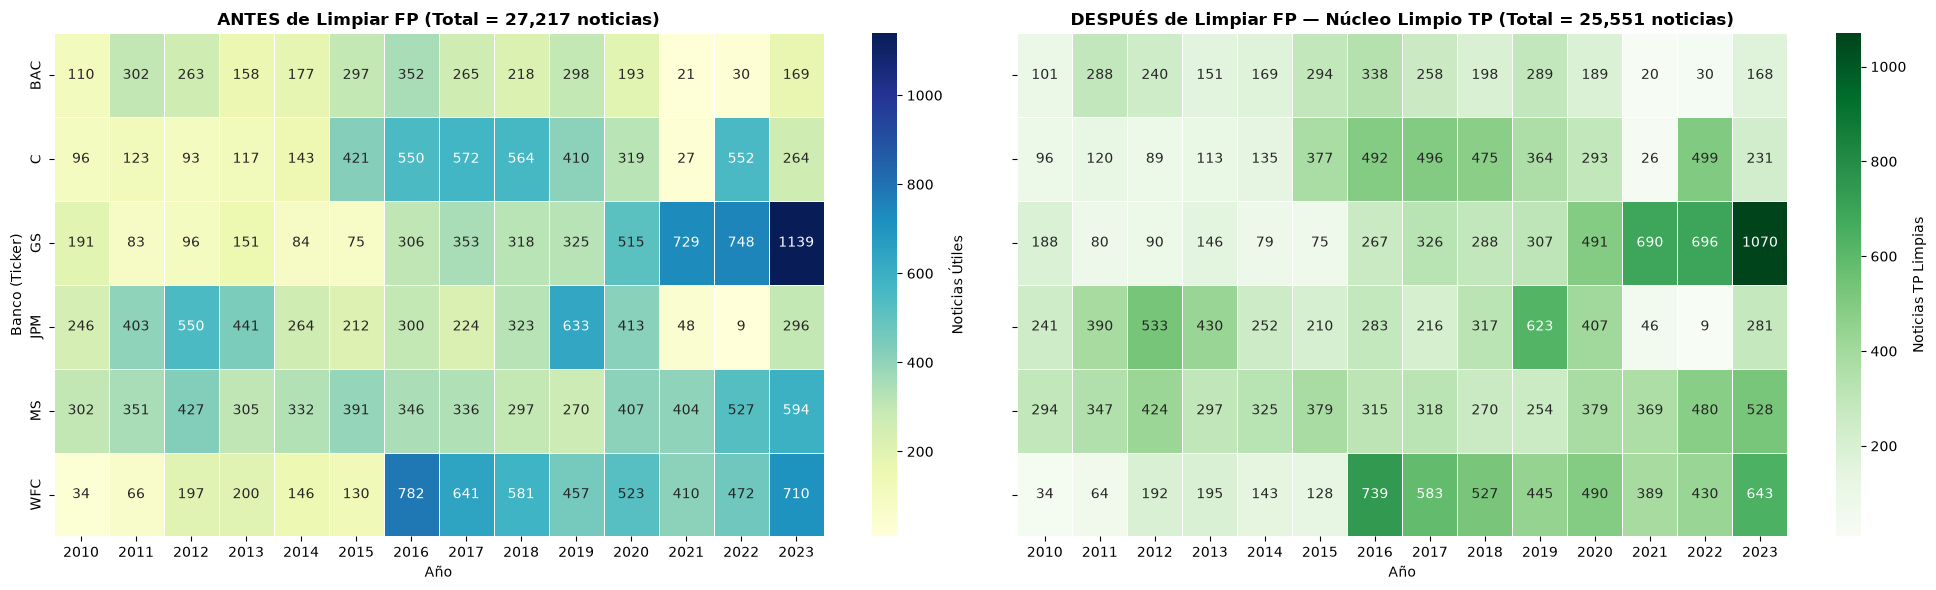

RESUMEN DE COBERTURA ANUAL POST-LIMPIEZA DE FALSOS POSITIVOS:


,Total_Antes,Total_Despues_TP,Años_con_0_Noticias,Minimo_Anual_TP,Año_del_Minimo
ticker,,,,,
BAC,2853,2733,0,20,2021
C,4251,3806,0,26,2021
GS,5113,4793,0,75,2015
JPM,4362,4238,0,9,2022
MS,5289,4979,0,254,2019
WFC,5349,5002,0,34,2010


In [5]:
df_tp = df_util[~df_util["es_fp_detectado"]].copy()
years_range = list(range(2010, 2024))

piv_antes = (
    df_util.groupby(["ticker", "year"]).size().unstack(fill_value=0)
    .reindex(columns=years_range, fill_value=0)
)
piv_despues = (
    df_tp.groupby(["ticker", "year"]).size().unstack(fill_value=0)
    .reindex(columns=years_range, fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharey=True)

sns.heatmap(
    piv_antes, annot=True, fmt="d", cmap="YlGnBu", linewidths=0.5,
    ax=axes[0], cbar_kws={"label": "Noticias Útiles"}
)
axes[0].set_title(f"ANTES de Limpiar FP (Total = {len(df_util):,} noticias)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Banco (Ticker)")

sns.heatmap(
    piv_despues, annot=True, fmt="d", cmap="Greens", linewidths=0.5,
    ax=axes[1], cbar_kws={"label": "Noticias TP Limpias"}
)
axes[1].set_title(f"DESPUÉS de Limpiar FP — Núcleo Limpio TP (Total = {len(df_tp):,} noticias)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Verificar mínimo anual por banco tras la limpieza
resumen_minimos = pd.DataFrame({
    "Total_Antes": piv_antes.sum(axis=1),
    "Total_Despues_TP": piv_despues.sum(axis=1),
    "Años_con_0_Noticias": (piv_despues == 0).sum(axis=1),
    "Minimo_Anual_TP": piv_despues.min(axis=1),
    "Año_del_Minimo": piv_despues.idxmin(axis=1),
})
print("RESUMEN DE COBERTURA ANUAL POST-LIMPIEZA DE FALSOS POSITIVOS:")
display(resumen_minimos)

---
## 6. Validación Final de Pureza: Muestra Aleatoria de 5 Noticias por Banco sobre el Núcleo Limpio (`TP`)

Finalmente, extraemos **5 noticias aleatorias por cada banco (`N = 30`)** tomadas exclusivamente del subconjunto depurado (`TP: Núcleo Limpio`) para verificar el salto de calidad y precisión frente a la muestra original sin depurar.

In [6]:
muestra_tp_limpia = (
    df_tp.groupby("ticker", group_keys=False)
    .sample(n=5, random_state=42)[cols_vista]
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)

print("=" * 105)
print("✔ MUESTRA ALEATORIA DE 5 NOTICIAS POR BANCO SOBRE EL NÚCLEO LIMPIO (POST-FILTRADO DE FP)")
print("=" * 105)
display(muestra_tp_limpia)

✔ MUESTRA ALEATORIA DE 5 NOTICIAS POR BANCO SOBRE EL NÚCLEO LIMPIO (POST-FILTRADO DE FP)


,date,ticker,category,confianza,fp_bucket,title,process_text
0,2010-10-08 14:28:00,BAC,credit,49.29,TP: Núcleo Limpio (Señal Válida),Foreclosures gone wild,"The failure of banks such as Bank of America Corp., J.P. Morgan Chase & Co. and now, reportedly, PNC Financial Services Group Inc. to properly review loan documents further underscores the cumbersome and complicated nature of loan origination."
1,2014-12-12 19:08:00,BAC,macro,40.84,TP: Núcleo Limpio (Señal Válida),Bank Of America Looks To End A Bumpy 2014 On A High Note,(Titular directo sin cuerpo)
2,2015-02-23 00:00:00,BAC,macro,45.57,TP: Núcleo Limpio (Señal Válida),"Cramer Gives Opinion On Bank Of America, Fiat Chrysler, Mastercard And Banco Santander",(Titular directo sin cuerpo)
3,2017-12-26 00:00:00,BAC,m&a,46.08,TP: Núcleo Limpio (Señal Válida),"Height Securities Highlights 65% Odds Of Significant Regulatory Relief For Financials In 2018; Citigroup, Zions Bancorp, Comerica, Regions Financial, JP Morgan, Goldman Sachs, Morgan Stanley & Bank Of America As Greatest Beneficiaries",(Titular directo sin cuerpo)
4,2020-06-12 20:57:00,BAC,m&a,54.56,TP: Núcleo Limpio (Señal Válida),Bank of America Stock Stands to Gain on Stress Test and Earnings,"The market narrative is so surreal that few people are likely paying attention to bank stocks’ performance, much less to one of the sector’s key event-driven trading opportunities."
5,2013-04-15 20:08:00,C,legal,47.01,TP: Núcleo Limpio (Señal Válida),Fed identifies living will weakness at banks,"iquidity at a unit of the big bank is another concern, the Fed said. There are eleven institutions submitting living wills: J.P. Morgan Chase & Co. , Citigroup Inc. , Wells Fargo , Goldman Sachs , Bank of America , Deutsche Bank , UBS , State Street , Morgan Stanley , Barclays and Bank of New York Mellon ."
6,2016-11-18 00:00:00,C,m&a,47.32,TP: Núcleo Limpio (Señal Válida),"Bank Stock Roundup: Trump Effect Makes Headlines, Citigroup in Focus","1. Post Brexit, Citigroup Inc.C is formulating the relocation of up to 900 jobs from London to Dublin. This is part of the company's contingency plan to deal with the growing uncertainties of Brexit. Citibank conducted a board meeting in Dublin last month and was trying to e"
7,2019-07-15 00:00:00,C,earnings,46.48,TP: Núcleo Limpio (Señal Válida),Citigroup Trades Higher On Q2 Earnings Beat,(Titular directo sin cuerpo)
8,2019-07-15 16:12:00,C,earnings,59.65,TP: Núcleo Limpio (Señal Válida),Citigroup and Other Banks Are Buying Back Their Stocks and That’s Good for Earnings,"The bank’s results provide a preview of what’s expected for JPMorgan, Bank of America, and Wells Fargo."
9,2022-05-02 00:00:00,C,legal,48.54,TP: Núcleo Limpio (Señal Válida),Citi CEO says sanctions will splinter global financial order,"ay 2 (Reuters) - Western countries' use of economic sanctions to punish Russia for its invasion of Ukraine is prompting some international clients of Citigroup Inc C.N to explore new ways to conduct trade and finance, the bank's chief executive said on Monday."
